# Burke GDP response, revisited: matched GWL 2.0, with Burke's own uncertainty

`pipeline/ramip_impacts_gdp_country.ipynb` applied Burke, Hsiang and Miguel's (2015) growth response at country level.
`method/audit/gdp_check.py` found four things to fix, and this notebook (plus `gdp/burke.py`, `gdp/country_tas.py`) does
them without touching the pipeline notebook:

1. **Burke's coefficients, exactly, with his uncertainty.** The paper's pooled regression is re-estimated from its
   replication panel (6,584 country-years, 166 countries; `raw/burke2015/`): 0.0127177 and −0.00048708, optimum 13.1 °C
   rather than the 12.7 °C the rounded pair implies. His 1000-draw country bootstrap gives the 5–95 % range of every
   money number. Two of his other specifications, the 5-lag cumulative response and the rich/poor split, are sensitivity rows.
2. **Observation-anchored temperature levels**, Burke's own construction: each country sits at its observed 1980–2010
   population-weighted mean plus his CMIP5 country-to-global warming ratio times the warming to 2 °C (GWL − 0.65 K), and the
   response is capped at 30 °C. The model supplies each year's anomaly about its parent-window mean, so the arm-minus-parent
   difference and the interannual spread are the model's, but the slope of Burke's curve is evaluated where the country
   actually is, not where each model puts it (they disagree by 3–10 K).
3. **Δg tested against its own same-forcing spread** (parent-member pairs of the same model at their own windows),
   per country and for the world total, instead of a KS test on monthly g(T) that only sees the largest shifts.
4. **Three framings of the money:** the one-year growth difference valued at the 2019 economy (as before), and the same
   difference sustained for 10 and 30 years, compounded.

Everything is arm minus parent at matched GWL 2.0 (windows as in the pipeline), in growth-rate units (0.001 = 0.1 pp of
annual GDP-per-capita growth) and constant-2015 US$; negative means the cleanup pathway is economically worse at the same
global temperature. Per-pair country temperatures come from the cache `diagnostics/gdp/country_tas_{model}.nc`, whose
first use here is a cross-check: with the rounded coefficients and the models' own levels it must reproduce the pipeline's Δg.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/code')
sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/path_independence')
sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/path_independence/gdp')
from funcs_support import get_params
import ks_tools as kt
import burke
from country_tas import ARMS, PARENT, POP_DIR

dir_list = get_params()
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 230)

GDP_DIR = dir_list['aux'] + 'diagnostics/gdp/'
DL_DIR  = dir_list['aux'] + 'data_layer/'
GWL_DIR = dir_list['aux'] + 'diagnostics/ramip_gwl/'
PRODUCT = dir_list['aux'] + 'gwl_timeseries.zarr'
out_dir = dir_list['aux'] + '../figures/e8_gdp_burke/'
os.makedirs(out_dir, exist_ok=True)
GWL, WIN, NDRAWS = 2.0, kt.WIN, 1000
LABEL = {'glob': '126aer (global cleanup)', 'eas': 'EAS126aer', 'sas': 'SAS126aer', 'afr': 'AFR126aer', 'nae': 'NAE126aer',
         'asia': 'ASIA126aer', 'safca': 'SAF126ca', 'sasca': 'SAS126ca'}
SPECS = {'pooled': 'pooled, no lags (main)', 'lag5': 'pooled, 5 lags, cumulative', 'richpoor': 'rich / poor, no lags'}

# Burke's three regressions, re-estimated from his panel with his 1000-draw country bootstrap (cached)
COEF = {}
for spec in SPECS:
    fn = GDP_DIR + f'burke_coef_{spec}.csv'
    if os.path.exists(fn):
        COEF[spec] = pd.read_csv(fn)
    else:
        COEF[spec] = burke.fit(spec, NDRAWS)
        COEF[spec].to_csv(fn, index=False)
    b1, b2, p1, p2 = burke.coefs(COEF[spec], spec)
    ok = b2[1:] < 0
    print(f'{SPECS[spec]:30s} temp {b1[0]:+.6f}  temp2 {b2[0]:+.7f}  optimum {-b1[0] / (2 * b2[0]):5.1f} C, '
          f'bootstrap 5-95 %: {np.percentile(-b1[1:][ok] / (2 * b2[1:][ok]), 5):.1f}-{np.percentile(-b1[1:][ok] / (2 * b2[1:][ok]), 95):.1f} C'
          + (f'; poor countries: temp {p1[0]:+.6f} temp2 {p2[0]:+.7f}' if p1 is not None else ''))
b1, b2 = burke.coefs(COEF['pooled'], 'pooled')[:2]
assert (round(b1[0], 4), round(b2[0], 4)) == (kt.B1, kt.B2), 'the pooled point estimate must round to the published pair'

# countries (the cache's order), World Bank economy, Burke's observational baselines
cty = pd.read_csv(GDP_DIR + 'countries.csv')
wb = pd.read_csv(DL_DIR + 'worldbank_gdp_pop.csv', index_col=0)
ALIAS = {'KOS': 'XKX', 'SDS': 'SSD', 'PSX': 'PSE'}                              # Natural Earth code -> World Bank code
econ = cty.set_index('iso3').join(wb[['gdp_pc', 'gdp', 'pop_wb']].rename(index={v: k for k, v in ALIAS.items()}))
econ['poor'] = econ.gdp_pc <= econ.gdp_pc.median()                             # Burke's projection rule: at or below the median GDP per capita
econ = econ.join(burke.baseline()[['meantemp', 'tconv']])
C, n_c = econ.index.values, len(econ)
has = (econ.meantemp.notna() & econ.gdp.notna()).values                        # countries that carry money: a baseline and a GDP
print(f'{n_c} countries; {int(econ.gdp.notna().sum())} with World Bank GDP; {int(econ.meantemp.notna().sum())} with a Burke baseline; '
      f'{int(has.sum())} with both ({100 * econ.gdp[has].sum() / econ.gdp.sum():.1f} % of world GDP)')
gdp_w = np.where(has, econ.gdp.fillna(0).values, 0.0)                          # US$ (constant 2015), 2019
pop_w = np.where(has, econ.pop_wb.fillna(0).values, 0.0); pop_w = pop_w / pop_w.sum()

# the country-temperature cache (gdp/country_tas.py)
TAS = {}
for mod in PARENT:
    fn = GDP_DIR + f'country_tas_{mod}.nc'
    if os.path.exists(fn):
        TAS[mod] = xr.open_dataset(fn).load()
        assert list(TAS[mod].country.values) == list(C)
print('models with the cache:', list(TAS))


def series(mod, exp, run, y0, y1):
    """annual country temperature (country, year) of one run over y0..y1, or None if those years are not all there"""
    ds = TAS[mod]
    i = np.flatnonzero((ds.exp.values == exp) & (ds.run.values == run))
    if len(i) != 1:
        return None
    v = ds.tas.isel(series=i[0]).sel(year=slice(y0, y1)).values.T
    return v if v.shape[1] == y1 - y0 + 1 and np.isfinite(v).all() else None

pooled, no lags (main)         temp +0.012718  temp2 -0.0004871  optimum  13.1 C, bootstrap 5-95 %: 9.9-16.7 C
pooled, 5 lags, cumulative     temp -0.003709  temp2 -0.0000967  optimum -19.2 C, bootstrap 5-95 %: -119.7-15.9 C
rich / poor, no lags           temp +0.008894  temp2 -0.0003154  optimum  14.1 C, bootstrap 5-95 %: 8.3-32.5 C; poor countries: temp +0.025433 temp2 -0.0007720


228 countries; 205 with World Bank GDP; 166 with a Burke baseline; 165 with both (98.9 % of world GDP)


models with the cache: ['CanESM5-1', 'CNRM-ESM2-1', 'EC-Earth3-AerChem', 'GISS-E2-1-G', 'MIROC6', 'MRI-ESM2-0', 'NorESM2-LM', 'UKESM1-0-LL', 'CESM2']


## Pairs, windows and the same-forcing null

The arm's ten window years against its parent's ten (same member; parent windows from the audited `gwl2.0_windows.csv`,
arm windows from the data product's `gwl` group), and every pair of usable parent members at their own windows as the null.

In [2]:
win_df = pd.read_csv(f'{GWL_DIR}gwl{GWL}_windows.csv')
_gmst = xr.open_zarr(PRODUCT, group='gmst')
_gwl = xr.open_zarr(PRODUCT, group='gwl')


def gwl_ends(mod, exp):
    ids = _gmst.run_id.sel(model=mod, exp=exp).values
    we = _gwl.window_end.sel(model=mod, exp=exp, gwl=GWL).values
    return {str(r): int(e) for r, e in zip(ids, we) if r and np.isfinite(e)}


def parent_pairs(mod, arm_exp):
    ends = gwl_ends(mod, arm_exp)
    rows = win_df[(win_df.model == mod) & win_df.usable]
    return [(r.run, int(r.anchor_end), ends[r.run]) for _, r in rows.iterrows() if r.run in ends]


rows, TP, TA = [], [], []
for arm, exp in ARMS.items():
    for mod in TAS:
        for run, ep, ea in parent_pairs(mod, exp):
            Tp, Ta = series(mod, PARENT[mod], run, ep - WIN + 1, ep), series(mod, exp, run, ea - WIN + 1, ea)
            if Tp is None or Ta is None:
                continue
            rows.append((arm, mod, run, ep, ea)); TP.append(Tp); TA.append(Ta)
pairs = pd.DataFrame(rows, columns=['arm', 'model', 'run', 'parent_end', 'arm_end'])
TP, TA = np.stack(TP), np.stack(TA)                                            # (pair, country, year)

nrows, NP0, NP1 = [], [], []
for mod in TAS:
    rr = [(r.run, int(r.anchor_end)) for _, r in win_df[(win_df.model == mod) & win_df.usable].iterrows()]
    S = {k: series(mod, PARENT[mod], k[0], k[1] - WIN + 1, k[1]) for k in rr}
    rr = [k for k in rr if S[k] is not None]
    for i, a in enumerate(rr):
        for b in rr[i + 1:]:
            nrows.append((mod, a[0], b[0])); NP0.append(S[a]); NP1.append(S[b])
null = pd.DataFrame(nrows, columns=['model', 'run_a', 'run_b'])
NP0, NP1 = np.stack(NP0), np.stack(NP1)
print('pairs per arm:', pairs.groupby('arm').size().to_dict())
print('null pairs per model:', null.groupby('model').size().to_dict())

# cross-check against the pipeline notebook: its dg (rounded coefficients, each model's own temperature level, no cap)
# must come out of this cache to float precision
old = pd.read_csv(dir_list['aux'] + 'diagnostics/impacts/burke_country_pairs.csv')
A0, B0 = burke.moments(TP, TA, cap=None)
chk = (pairs.join(pd.DataFrame(kt.B1 * A0 + kt.B2 * B0, columns=C)).melt(id_vars=list(pairs.columns), var_name='iso3', value_name='dg_new')
            .merge(old[['arm', 'model', 'run', 'iso3', 'dg']], on=['arm', 'model', 'run', 'iso3']))
print(f'cross-check vs ramip_impacts_gdp_country: {len(chk)} pair-country rows, max |dg difference| {float((chk.dg - chk.dg_new).abs().max()):.1e}')
assert len(chk) == len(old) and (chk.dg - chk.dg_new).abs().max() < 1e-5

pairs per arm: {'afr': 58, 'asia': 16, 'eas': 67, 'glob': 72, 'nae': 66, 'safca': 10, 'sas': 62, 'sasca': 12}
null pairs per model: {'CESM2': 45, 'CNRM-ESM2-1': 15, 'CanESM5-1': 45, 'EC-Earth3-AerChem': 15, 'GISS-E2-1-G': 45, 'MIROC6': 45, 'MRI-ESM2-0': 45, 'UKESM1-0-LL': 45}


cross-check vs ramip_impacts_gdp_country: 82764 pair-country rows, max |dg difference| 3.9e-07


## Δg at the observation-anchored level, three specifications, 1000 coefficient draws

`dg[spec]` is (draw, pair, country); draw 0 is the point estimate. Money is summed per model first and then averaged over
models, so a model with more pairs does not dominate.

In [3]:
def anchored(T0, T1, base=burke.GMST_1980_2010):
    """both sides at Burke's level for this country in a `GWL` world, keeping the model's anomalies about its parent-window mean"""
    L = (econ.meantemp + econ.tconv * (GWL - base)).values[None, :, None]
    ref = T0.mean(-1, keepdims=True)
    return L + (T0 - ref), L + (T1 - ref)


poor = econ.poor.values[None, :]
Tp3, Ta3 = anchored(TP, TA)
A3, B3 = burke.moments(Tp3, Ta3)
An, Bn = burke.moments(*anchored(NP0, NP1))
DG = {spec: burke.dg(COEF[spec], spec, A3, B3, poor) for spec in SPECS}          # (draw, pair, country)
DGN = {spec: burke.dg(COEF[spec], spec, An, Bn, poor)[0] for spec in SPECS}      # point estimate, (null pair, country)
dT = TA.mean(-1) - TP.mean(-1)                                                   # K, the model's own arm-minus-parent

gi = pairs.groupby(['arm', 'model']).indices
BM = {spec: {k: np.where(has, DG[spec][:, idx].mean(1), 0.0) for k, idx in gi.items()} for spec in SPECS}   # (draw, country) per (arm, model)

# world totals per (spec, arm, model, draw): one year's growth difference valued at the 2019 economy, and population-weighted dg
tot = pd.concat([pd.DataFrame({'spec': spec, 'arm': a, 'model': m, 'draw': np.arange(v.shape[0]),
                               'dgdp_bn': v @ gdp_w / 1e9, 'dg_popw': v @ pop_w})
                 for spec in SPECS for (a, m), v in BM[spec].items()])
mm = tot.groupby(['spec', 'arm', 'draw'])[['dgdp_bn', 'dg_popw']].mean()         # model mean, per draw
totals = pd.concat([
    tot[tot.draw == 0].groupby(['spec', 'arm']).agg(models=('model', 'nunique'), dgdp_bn=('dgdp_bn', 'mean'), model_sd=('dgdp_bn', 'std'),
                                                    dg_popw=('dg_popw', 'mean'), dg_popw_sd=('dg_popw', 'std'),
                                                    models_negative=('dgdp_bn', lambda s: int((s < 0).sum()))),
    mm[mm.index.get_level_values('draw') > 0].groupby(['spec', 'arm']).dgdp_bn.agg(coef_p05=lambda s: s.quantile(0.05), coef_p95=lambda s: s.quantile(0.95),
                                                                                    coef_frac_negative=lambda s: (s < 0).mean())], axis=1)
# the same growth difference sustained for N years, compounded, as a share of world GDP (countries with money)
for N in (10, 30):
    g = pd.Series({(spec, a, m): ((1 + v[0]) ** N - 1) @ gdp_w / gdp_w.sum() for spec in SPECS for (a, m), v in BM[spec].items()})
    g.index.names = ['spec', 'arm', 'model']
    totals[f'sustained_{N}yr_pct_gdp'] = 100 * g.groupby(level=['spec', 'arm']).mean()
totals = totals.reset_index()
totals.to_csv(GDP_DIR + 'gdp_totals.csv', index=False)
tot.to_csv(GDP_DIR + 'gdp_totals_by_model_draw.csv', index=False)

ARM_ORDER = ['glob', 'eas', 'sas', 'afr', 'nae', 'asia', 'safca', 'sasca']
show = totals.set_index(['spec', 'arm']).reindex([('pooled', a) for a in ARM_ORDER]).reset_index(level=0, drop=True)
print('main specification (pooled, no lags): world dGDP, arm minus parent at matched GWL 2.0, bn constant-2015 US$ per year of growth')
print(show[['models', 'dgdp_bn', 'model_sd', 'coef_p05', 'coef_p95', 'coef_frac_negative', 'models_negative', 'dg_popw', 'sustained_10yr_pct_gdp', 'sustained_30yr_pct_gdp']].round(3).to_string())
print('\nby specification, world dGDP bn/yr (model mean; coefficient 5-95 %):')
sp = totals.set_index(['arm', 'spec']).reindex([(a, s) for a in ARM_ORDER[:5] for s in SPECS])
print(sp[['dgdp_bn', 'model_sd', 'coef_p05', 'coef_p95', 'coef_frac_negative']].round(2).to_string())

# what each fix changed, global cleanup, pooled point estimate: the ladder from the pipeline's number to this one
b1x, b2x = burke.coefs(COEF['pooled'], 'pooled')[:2]
ladder = {}
for name, (bb1, bb2, AA, BB) in {'V0 pipeline: rounded coefficients, model levels, no cap': (kt.B1, kt.B2, A0, B0),
                                 'V1 exact coefficients': (b1x[0], b2x[0], A0, B0),
                                 'V3 observation-anchored level, 30 C cap (this notebook)': (b1x[0], b2x[0], A3, B3)}.items():
    d = bb1 * AA + bb2 * BB
    ladder[name] = pd.Series({a: np.mean([np.where(has, d[idx].mean(0), 0) @ gdp_w / 1e9 for (aa, m), idx in gi.items() if aa == a]) for a in ARM_ORDER[:5]})
for base in (0.5, 0.8):
    Ab, Bb = burke.moments(*anchored(TP, TA, base))
    d = b1x[0] * Ab + b2x[0] * Bb
    ladder[f'V3 with the 1980-2010 GMST offset at {base} K'] = pd.Series({a: np.mean([np.where(has, d[idx].mean(0), 0) @ gdp_w / 1e9 for (aa, m), idx in gi.items() if aa == a]) for a in ARM_ORDER[:5]})
ladder = pd.DataFrame(ladder).T
ladder.to_csv(GDP_DIR + 'gdp_variants.csv')
print('\nworld dGDP bn/yr by variant (model mean of per-model totals; V0 differs from the pipeline only by the countries without a baseline):')
print(ladder.round(1).to_string())

main specification (pooled, no lags): world dGDP, arm minus parent at matched GWL 2.0, bn constant-2015 US$ per year of growth
       models  dgdp_bn  model_sd  coef_p05  coef_p95  coef_frac_negative  models_negative  dg_popw  sustained_10yr_pct_gdp  sustained_30yr_pct_gdp
arm                                                                                                                                               
glob        8  -34.783    21.789   -78.294    12.206               0.895                7   -0.001                  -0.409                  -1.187
eas         8  -19.558    14.855   -37.426    -0.993               0.957                7   -0.000                  -0.231                  -0.676
sas         7  -15.348    10.969   -22.400    -8.219               0.999                6   -0.001                  -0.180                  -0.522
afr         8   -4.082    20.774    -6.551    -1.667               0.993                4   -0.000                  -0.047                

## Per country: Δg, its spread, the test against the same-forcing null, and the money

Z per (arm, model, country) is the mean Δg over the arm's pairs divided by the same-forcing standard deviation of Δg (null pairs
of that model) over √n; models are combined with Stouffer's method. 5 % of countries fall beyond |Z| = 1.96 by chance. The
same for the world total.

In [4]:
sd0 = {mod: DGN['pooled'][null.model.values == mod].std(0, ddof=1) for mod in TAS if (null.model == mod).sum() >= 3}
Zc = {}
for arm in ARMS:
    zs = [DG['pooled'][0, idx].mean(0) / (sd0[m] / np.sqrt(len(idx))) for (a, m), idx in gi.items() if a == arm and m in sd0]
    Zc[arm] = np.sum(zs, 0) / np.sqrt(len(zs)) if zs else np.full(n_c, np.nan)
null_tot = pd.Series(np.where(has, DGN['pooled'], 0) @ gdp_w / 1e9).groupby(null.model.values).std(ddof=1)
rec = []
for (a, m), idx in gi.items():
    if m in null_tot.index:
        t = np.where(has, DG['pooled'][0, idx], 0) @ gdp_w / 1e9
        rec.append((a, m, t.mean() / (null_tot[m] / np.sqrt(len(idx)))))
Zt = pd.DataFrame(rec, columns=['arm', 'model', 'z']).groupby('arm').z.apply(lambda s: s.sum() / np.sqrt(len(s)))

summ = []
for arm in ARMS:
    ms = [v for (a, m), v in BM['pooled'].items() if a == arm]
    if not ms:
        continue
    M = np.stack(ms)                                                             # (model, draw, country)
    pt = M[:, 0].mean(0)                                                         # model mean, point estimate
    dd = M[:, 1:].mean(0)                                                        # model mean per draw
    d = pd.DataFrame({'arm': arm, 'iso3': C, 'models': len(ms), 'pairs': sum(len(idx) for (a, m), idx in gi.items() if a == arm),
                      'dT': np.stack([dT[idx].mean(0) for (a, m), idx in gi.items() if a == arm]).mean(0),
                      'dg': pt, 'dg_model_sd': M[:, 0].std(0, ddof=1), 'dg_coef_p05': np.percentile(dd, 5, 0), 'dg_coef_p95': np.percentile(dd, 95, 0),
                      'models_negative': (M[:, 0] < 0).sum(0), 'Z': Zc[arm]})
    summ.append(d)
summ = pd.concat(summ).join(econ[['name', 'gdp_pc', 'gdp', 'pop_wb', 'poor', 'meantemp']], on='iso3')
summ['T_level'] = summ.meantemp + econ.tconv.reindex(summ.iso3).values * (GWL - burke.GMST_1980_2010)
summ.loc[~summ.iso3.map(dict(zip(C, has))).values, ['dg', 'dg_model_sd', 'dg_coef_p05', 'dg_coef_p95', 'Z']] = np.nan
summ['dgdp_pc'] = summ.dg * summ.gdp_pc                                          # US$ per person, one year
summ['dgdp_bn'] = summ.dg * summ.gdp / 1e9                                       # bn US$, one year
summ['dgdp_bn_30yr'] = ((1 + summ.dg) ** 30 - 1) * summ.gdp / 1e9
summ.to_csv(GDP_DIR + 'gdp_country.csv', index=False)
sig = pd.DataFrame({'countries_beyond_1.96': {a: float(np.mean(np.abs(Zc[a][has]) > 1.96)) for a in ARMS}, 'world_total_Z': Zt}).reindex(ARM_ORDER)
sig.to_csv(GDP_DIR + 'gdp_significance.csv')
print('dg against its same-forcing spread (fraction of countries beyond |Z| = 1.96; 0.05 by chance) and the world total:')
print(sig.round(3).to_string())
for arm in ['glob', 'eas', 'sas']:
    s = summ[(summ.arm == arm)].dropna(subset=['dgdp_bn'])
    top = s.reindex(s.dgdp_bn.abs().sort_values(ascending=False).index).head(10)
    print(f'\n{LABEL[arm]}: 10 largest |dGDP| (dg in growth units; dgdp_pc US$/person; dgdp bn US$; one year at the 2019 economy):')
    print(top[['name', 'T_level', 'dT', 'dg', 'dg_model_sd', 'dg_coef_p05', 'dg_coef_p95', 'models_negative', 'models', 'Z', 'dgdp_pc', 'dgdp_bn', 'dgdp_bn_30yr']].round(4).to_string(index=False))

dg against its same-forcing spread (fraction of countries beyond |Z| = 1.96; 0.05 by chance) and the world total:
       countries_beyond_1.96  world_total_Z
glob                   0.691        -13.173
eas                    0.218         -7.919
sas                    0.194         -5.152
afr                    0.315         -1.712
nae                    0.436         -0.766
asia                   0.242         -4.162
safca                  0.139         -1.598
sasca                  0.242          0.246

126aer (global cleanup): 10 largest |dGDP| (dg in growth units; dgdp_pc US$/person; dgdp bn US$; one year at the 2019 economy):
                    name  T_level     dT      dg  dg_model_sd  dg_coef_p05  dg_coef_p95  models_negative  models        Z  dgdp_pc  dgdp_bn  dgdp_bn_30yr
                   China  15.9423 0.3574 -0.0011       0.0007      -0.0023       0.0001                8       8 -18.4860 -11.6057 -16.3378     -482.2535
                   India  27.1979 0.2345 -0.0033     

## Figures

`gdp_totals.png`: world ΔGDP per arm and specification with the model spread and Burke's coefficient range; `gdp_variants.png`:
what each fix changed; `gdp_map_{arm}.png`: Δg, Z, ΔGDP per capita and ΔGDP by country; `gdp_top20_glob.png`.

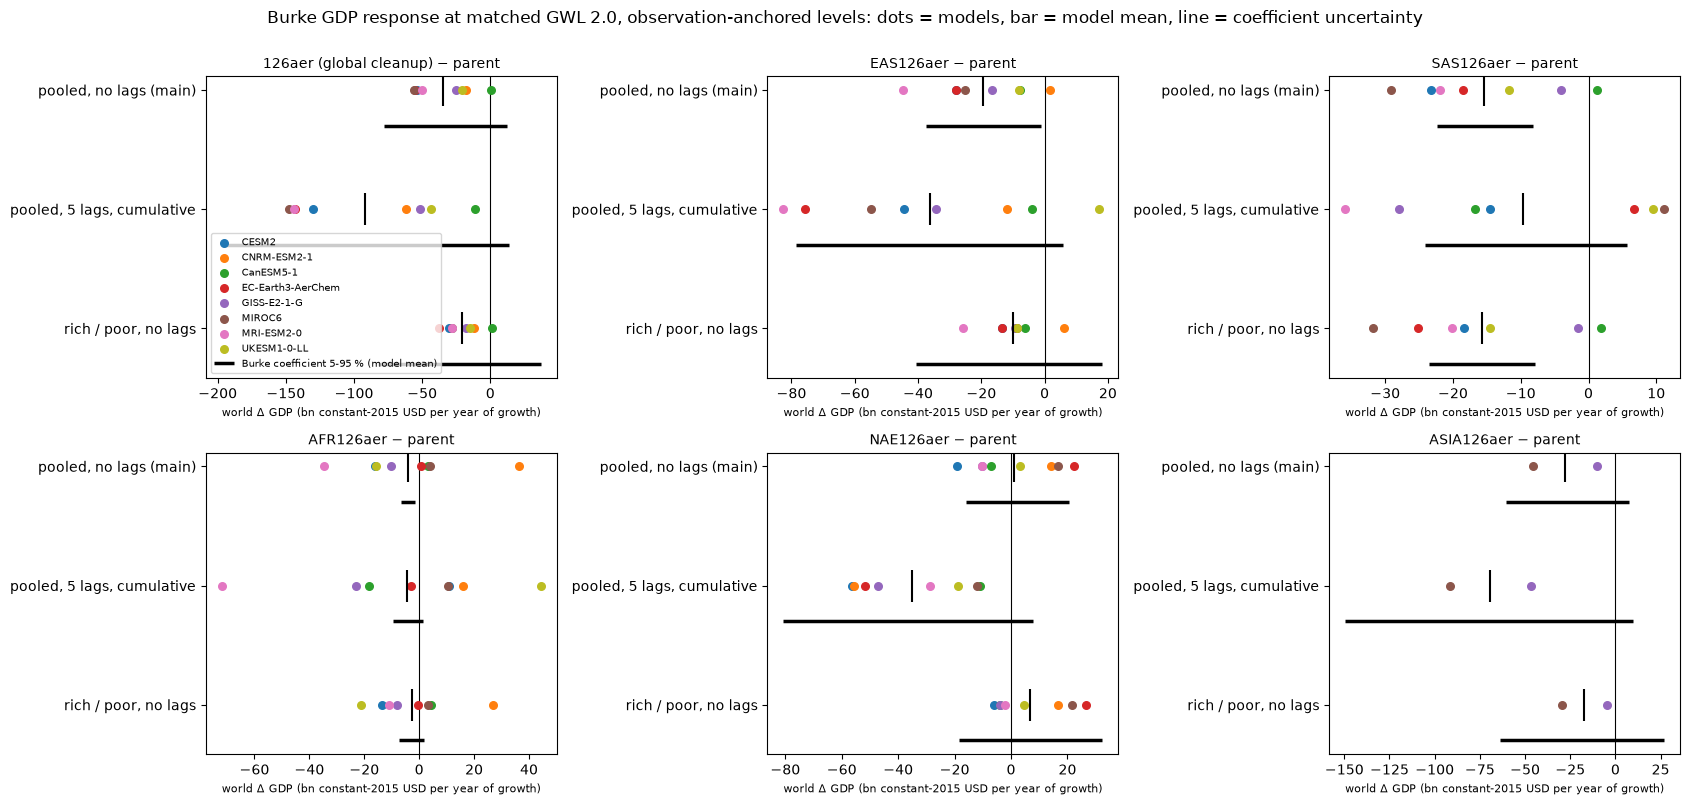

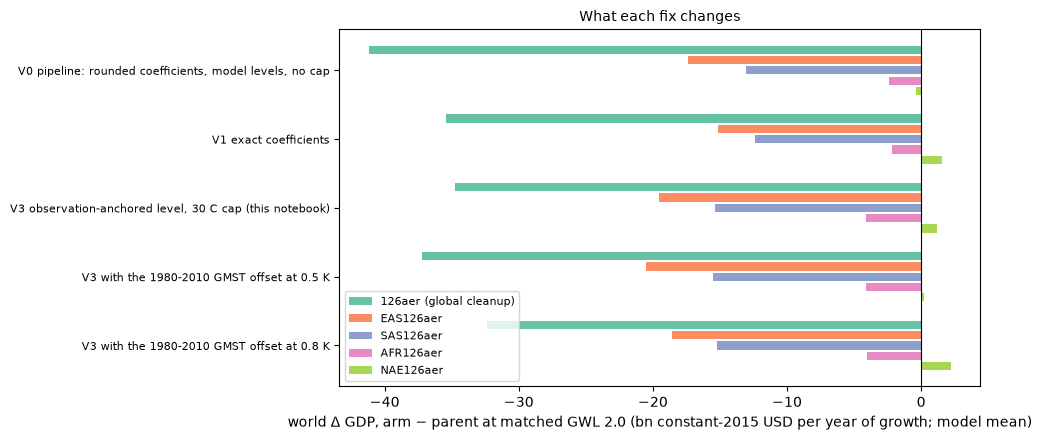

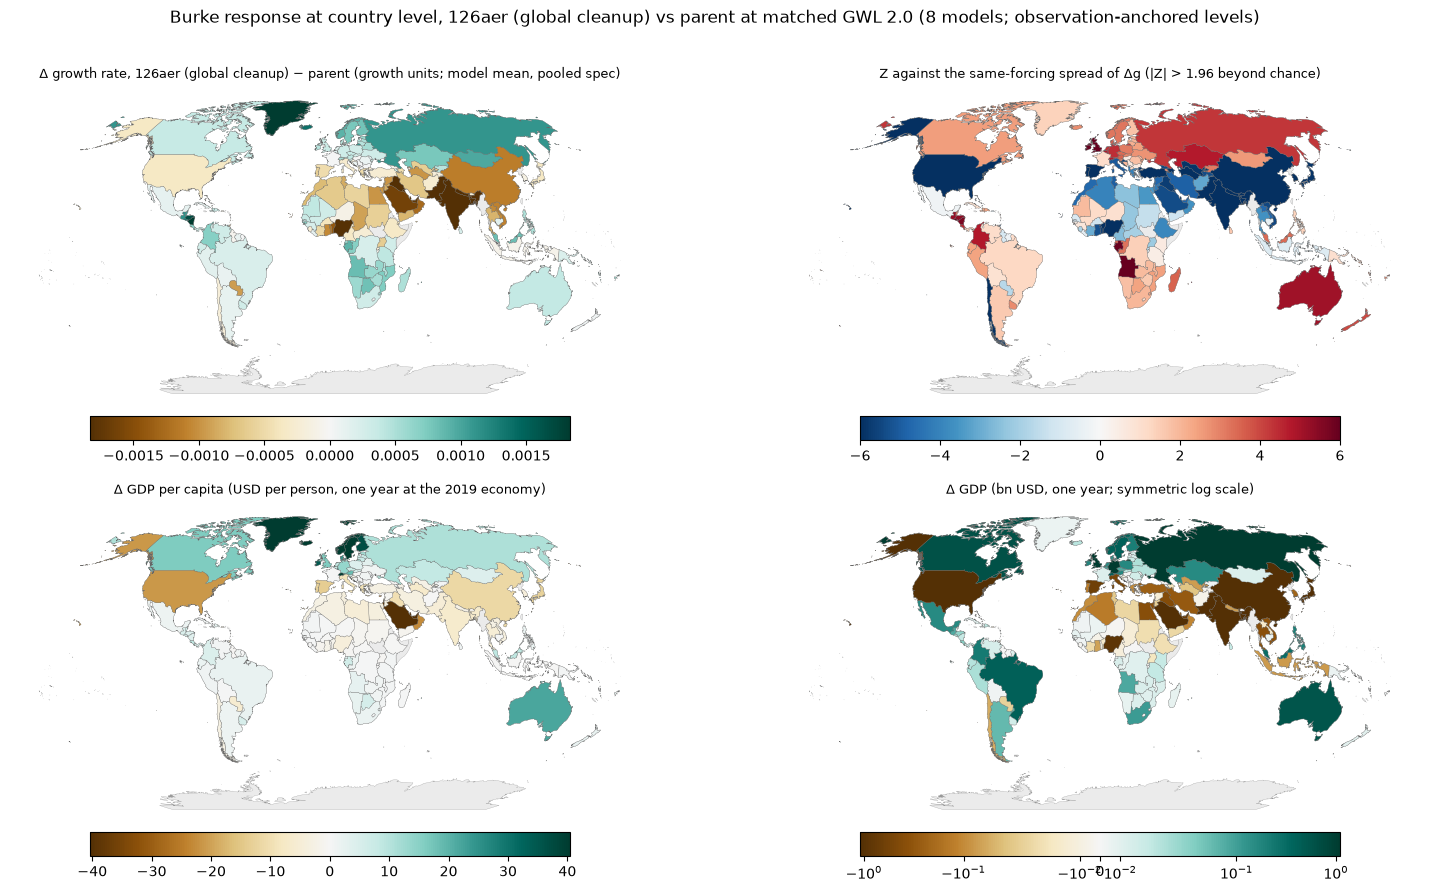

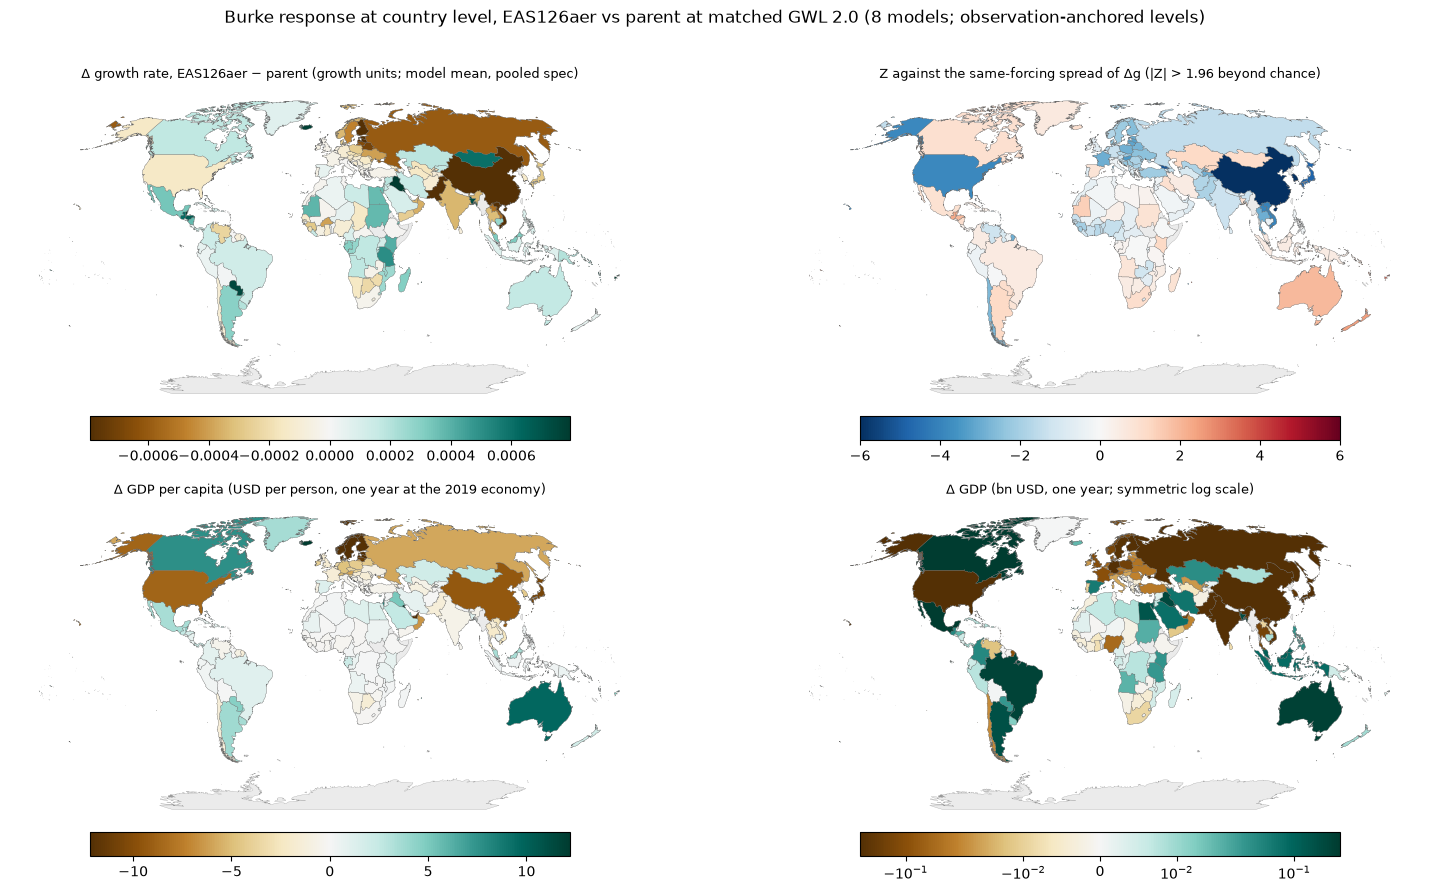

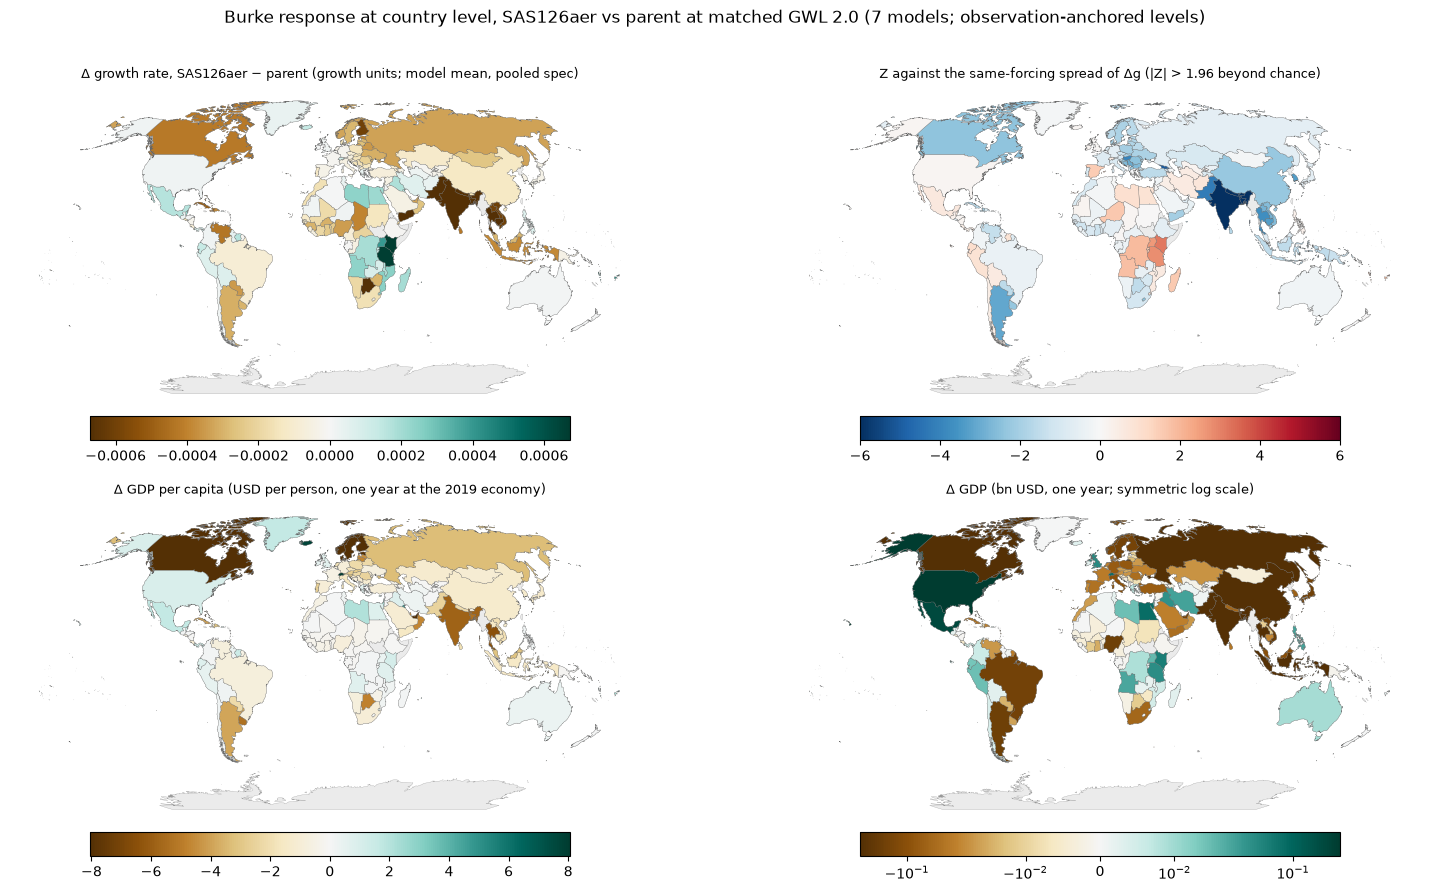

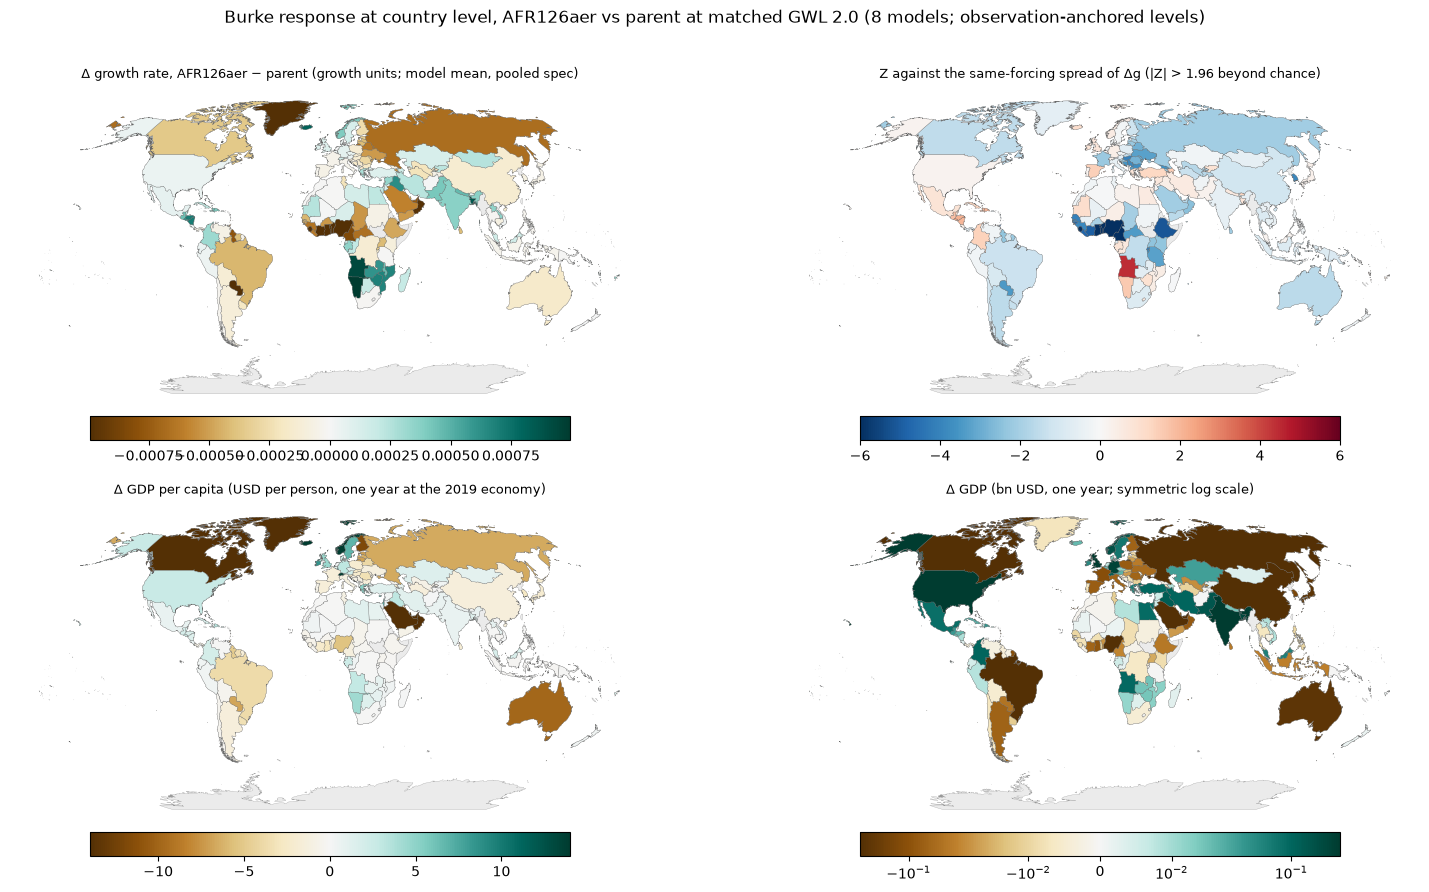

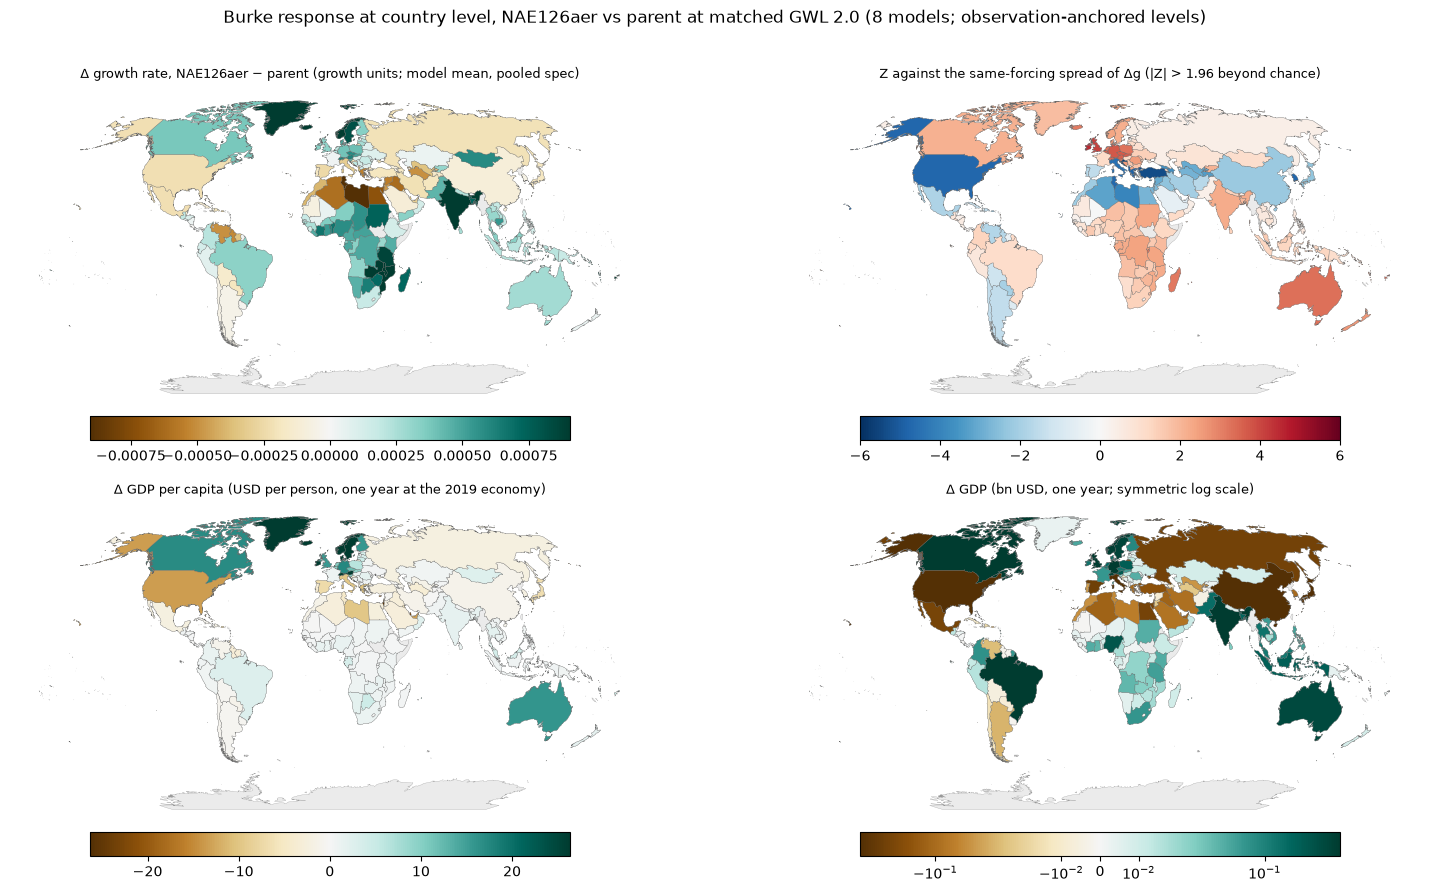

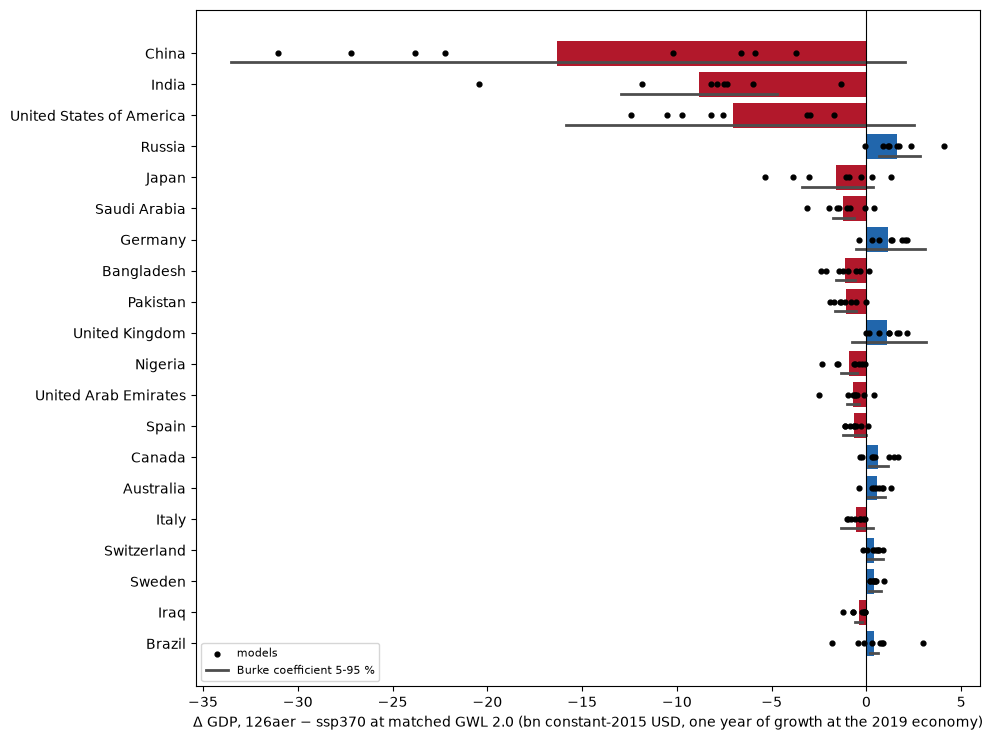

figures in /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e8_gdp_burke/


In [5]:
import geopandas as gpd
ne = gpd.read_file('zip://' + POP_DIR + 'ne_50m_admin_0_countries.zip').dissolve(by='ADM0_A3', aggfunc='first').reset_index()
world = ne[['ADM0_A3', 'geometry']].rename(columns={'ADM0_A3': 'iso3'}).to_crs('ESRI:54030')
MODS = sorted(TAS)
col = dict(zip(MODS, plt.cm.tab10(np.arange(len(MODS)))))

fig, axs = plt.subplots(2, 3, figsize=(17, 8), sharex=False)
for ax, arm in zip(axs.flat, ARM_ORDER[:6]):
    for j, spec in enumerate(SPECS):
        t = tot[(tot.arm == arm) & (tot.spec == spec)]
        for m, v in t[t.draw == 0].set_index('model').dgdp_bn.items():
            ax.scatter(v, j, color=col[m], s=30, zorder=3, label=m if (arm, j) == ('glob', 0) else None)
        r = totals[(totals.arm == arm) & (totals.spec == spec)].iloc[0]
        ax.scatter(r.dgdp_bn, j, marker='|', color='k', s=500, zorder=4)
        ax.plot([r.coef_p05, r.coef_p95], [j + 0.3] * 2, color='k', lw=2.5, solid_capstyle='butt',
                label='Burke coefficient 5-95 % (model mean)' if (arm, j) == ('glob', 0) else None)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_yticks(range(len(SPECS)), [SPECS[s] for s in SPECS]); ax.invert_yaxis()
    ax.set_title(f'{LABEL[arm]} − parent', fontsize=10)
    ax.set_xlabel('world Δ GDP (bn constant-2015 USD per year of growth)', fontsize=8)
axs[0, 0].legend(fontsize=7, loc='lower left')
fig.suptitle('Burke GDP response at matched GWL 2.0, observation-anchored levels: dots = models, bar = model mean, line = coefficient uncertainty', y=1.0)
fig.tight_layout(); fig.savefig(out_dir + 'gdp_totals.png', dpi=150, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
for j, (name, r) in enumerate(ladder.iterrows()):
    for a, off in zip(ARM_ORDER[:5], np.linspace(-0.3, 0.3, 5)):
        ax.barh(j + off, r[a], height=0.12, color=plt.cm.Set2(ARM_ORDER.index(a)), label=LABEL[a] if j == 0 else None)
ax.axvline(0, color='k', lw=0.8); ax.set_yticks(range(len(ladder)), ladder.index, fontsize=8); ax.invert_yaxis()
ax.set_xlabel('world Δ GDP, arm − parent at matched GWL 2.0 (bn constant-2015 USD per year of growth; model mean)')
ax.legend(fontsize=8); ax.set_title('What each fix changes', fontsize=10)
fig.tight_layout(); fig.savefig(out_dir + 'gdp_variants.png', dpi=150, bbox_inches='tight'); plt.show()


def choropleth(ax, d, colname, title, cmap, lim=None, log=False, vmin=None):
    v = d[colname]
    if lim is None:
        lim = float(np.nanpercentile(v.abs(), 95))
    norm = mcolors.SymLogNorm(linthresh=lim / 20, vmin=-lim, vmax=lim) if log else mcolors.Normalize(-lim if vmin is None else vmin, lim)
    world.plot(ax=ax, color='0.92', edgecolor='0.6', linewidth=0.2)
    d.dropna(subset=[colname]).plot(ax=ax, column=colname, cmap=cmap, norm=norm, edgecolor='0.4', linewidth=0.2, legend=True,
                                    legend_kwds={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.02})
    ax.set_title(title, fontsize=9); ax.set_axis_off()


for arm in ['glob', 'eas', 'sas', 'afr', 'nae']:
    d = world.join(summ[summ.arm == arm].set_index('iso3')[['dg', 'Z', 'dgdp_pc', 'dgdp_bn']], on='iso3')
    fig, axs = plt.subplots(2, 2, figsize=(16, 9))
    choropleth(axs[0, 0], d, 'dg', f'Δ growth rate, {LABEL[arm]} − parent (growth units; model mean, pooled spec)', 'BrBG')
    choropleth(axs[0, 1], d, 'Z', 'Z against the same-forcing spread of Δg (|Z| > 1.96 beyond chance)', 'RdBu_r', lim=6)
    choropleth(axs[1, 0], d, 'dgdp_pc', 'Δ GDP per capita (USD per person, one year at the 2019 economy)', 'BrBG')
    choropleth(axs[1, 1], d, 'dgdp_bn', 'Δ GDP (bn USD, one year; symmetric log scale)', 'BrBG', log=True)
    n = summ[summ.arm == arm].models.max()
    fig.suptitle(f'Burke response at country level, {LABEL[arm]} vs parent at matched GWL 2.0 ({n} models; observation-anchored levels)', y=0.995)
    fig.tight_layout(); fig.savefig(out_dir + f'gdp_map_{arm}.png', dpi=140, bbox_inches='tight'); plt.show()

g = summ[summ.arm == 'glob'].dropna(subset=['dgdp_bn'])
top = g.reindex(g.dgdp_bn.abs().sort_values(ascending=False).index).head(20)
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(top.name, top.dgdp_bn, color=np.where(top.dgdp_bn < 0, '#b2182b', '#2166ac'))
for i, iso in enumerate(top.iso3):
    c = list(C).index(iso)
    pm = [v[0, c] * gdp_w[c] / 1e9 for (a, m), v in BM['pooled'].items() if a == 'glob']
    ax.scatter(pm, np.full(len(pm), i), s=12, color='k', zorder=3, label='models' if i == 0 else None)
    ax.plot([top.dg_coef_p05.iloc[i] * top.gdp.iloc[i] / 1e9, top.dg_coef_p95.iloc[i] * top.gdp.iloc[i] / 1e9], [i + 0.3] * 2,
            color='0.3', lw=2, label='Burke coefficient 5-95 %' if i == 0 else None)
ax.axvline(0, color='k', lw=0.8); ax.invert_yaxis(); ax.legend(fontsize=8)
ax.set_xlabel('Δ GDP, 126aer − ssp370 at matched GWL 2.0 (bn constant-2015 USD, one year of growth at the 2019 economy)')
fig.tight_layout(); fig.savefig(out_dir + 'gdp_top20_glob.png', dpi=150, bbox_inches='tight'); plt.show()
print('figures in', out_dir)

## Reading the results

**Burke's framework, done his way, keeps the sign and roughly the size of the pipeline's number, with an uncertainty wider than the
model spread.** Global cleanup at matched 2 °C: −34.8 ± 21.8 bn US$ per year of growth (mean ± sd over 8 models; 7 of 8
negative), with Burke's own coefficient uncertainty spanning −78 to +12 bn (90 % of the 1000 bootstrap draws; 90 % of draws
negative). The pipeline's −41.9 bn becomes −35.4 with the exact coefficients (the rounded pair steepens the curve above 13 °C by
about 20 %) and −34.8 with observation-anchored levels and the 30 °C cap. The anchoring mainly removes model disagreement: the
model sd falls from 35 to 22 bn, because China, the United States and Japan sit within 1 K of Burke's optimum, where the slope
changes sign, and each model had put them somewhere different (13.2–16.6 °C for China). The 1980–2010 GMST offset (0.5–0.8 K in
place of 0.65) moves the world total by ±2.5 bn.

**Where it comes from.** China −16.3 bn (its coefficient range, −0.0023 to +0.0001 growth units, includes zero: at 15.9 °C the
sign depends on where the optimum is), India −8.8 bn (robust: −0.0048 to −0.0018), the United States −7.0 bn; Russia +1.6,
Germany +1.1 and the United Kingdom +1.1 bn gain. India, Bangladesh, Pakistan and Saudi Arabia lose 0.3–0.4 pp of one year's
growth; nothing in Europe or North America moves by more than 0.03 pp.

**The regional arms.** EAS −19.6 ± 14.9 bn (coefficient range −37 to −1; China −13.2), SAS −15.3 ± 11.0 (−22 to −8; India −8.1,
Bangladesh −0.9), AFR −4.1 ± 20.8 (−6.6 to −1.7 for the model mean, but 4 of 8 models positive), NAE +1.2 ± 15.1 with no sign
(−16 to +21). ASIA, SAF-ca and SAS-ca rest on 2–3 models.

**Detectable against internal variability.** Tested against the same-forcing spread of Δg itself, the global cleanup's loss is
beyond chance in 69 % of countries (5 % expected) with a world-total Z of −13; EAS (−7.9) and SAS (−5.2) are clear, AFR (−1.7)
and NAE (−0.8) are not. The KS test on monthly g(T) that the pipeline used rejected at the null rate (5.8 % vs 4.7 %): it was the
wrong instrument, not evidence of no effect. What bounds the money numbers is Burke's regression and the model spread, not noise.

**Specification.** The 5-lag cumulative response, re-estimated from the same panel, has no identified optimum (bootstrap 5–95 %:
−120 to +16 °C) and is negative at every temperature in the sample, so under it any warming costs and the totals grow (global
cleanup −92 bn, NAE −35 bn) with ranges that include zero; the rich/poor split gives −21 bn (−82 to +37). The pooled no-lag
response is the paper's headline specification and the one quoted here.

**Framing.** −34.8 bn is one year's growth difference valued at the 2019 economy, 0.04 % of world GDP. Held for 10 years it
compounds to −0.41 % of world GDP, for 30 years to −1.2 %; `ramip_gdp_pathway.ipynb` follows the actual pathways instead.
165 countries carry money (98.9 % of world GDP); Mali, Mauritania and Niger are capped at 30 °C. Matching on warming level removes
the cleanup's extra global warming by construction, and Burke's function knows nothing about air quality: this is the cost of
where the warming lands at a fixed global temperature, not the cost of cleaning up.